## PROBLEMA  2:  MEJORANDO  LA  EFICIENCIA  ENERGÉTICA  EN  LA UPM

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### **2.1 - Estudio del Dataset**

#### 2.1.1 - Estudio detallado, cualitativo y cuantitativo

In [6]:
# Recogida de datos: 
consumo = pd.read_csv("datos/consumo_campus.csv", parse_dates=["fecha_hora"], index_col="fecha_hora")
bloques = pd.read_csv("datos/bloques.csv")
meteo = pd.read_csv("datos/meteorologia.csv", parse_dates=["fecha_hora"], index_col="fecha_hora")

##### 2.1.1.1 - Estudio del dataset de consumo

In [7]:
# Análisis del DataFrame de consumo
consumo.head(3)

,NOR_001,NOR_002,NOR_003,NOR_004,NOR_005,NOR_006,NOR_007,NOR_008,NOR_009,NOR_010,...,SUR_128,SUR_129,SUR_130,SUR_131,SUR_132,SUR_133,SUR_134,SUR_135,SUR_136,SUR_137
fecha_hora,,,,,,,,,,,,,,,,,,,,,
2016-01-01 00:00:00,0.11,44.62,350.14,430.38,1268.09,53.24,54.47,44.48,NaN,725.68,...,6.07,10.95,1763.15,197.97,50.79,7.45,106.97,1.20,341.53,83.65
2016-01-01 01:00:00,0.11,44.26,347.66,428.81,1325.05,53.81,55.79,44.17,NaN,724.55,...,6.26,10.52,1760.75,197.23,50.33,7.45,107.16,1.19,334.17,81.89
2016-01-01 02:00:00,0.11,45.21,320.58,423.89,1311.70,53.93,54.20,46.32,NaN,723.90,...,6.48,10.19,1768.16,195.55,51.04,7.44,107.67,1.19,340.08,79.84


Se observa que el dataset `consumo` presenta la información del **consumo energético en kWh de cada bloque en cada campus** (NOR, SUR y REC) a cada hora dada por `fecha_hora`.

##### 2.1.1.2 - Estudio del dataset de bloques

In [8]:
# Análisis del DataFrame de bloques
display(bloques.head(3))
display(bloques.info())

,bloque,campus,uso,superficie_m2,anio_construccion,plantas,ocupacion
0,NOR_001,Campus Norte,Docente,609.8,1909.0,3.0,NaN
1,NOR_002,Campus Norte,Docente,4079.4,1912.0,5.0,NaN
2,NOR_003,Campus Norte,Docente,10181.1,1994.0,8.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 281 entries, 0 to 280
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bloque             281 non-null    object 
 1   campus             281 non-null    object 
 2   uso                281 non-null    object 
 3   superficie_m2      281 non-null    float64
 4   anio_construccion  226 non-null    float64
 5   plantas            144 non-null    float64
 6   ocupacion          0 non-null      float64
dtypes: float64(4), object(3)
memory usage: 15.5+ KB


None

Este dataset `bloques` ofrece información con respecto a los bloques de cada campus, como su uso, superficie o año de construcción. Se observa que tanto `campus`como `uso` pueden usarse con tipo de dato `category`, mientras que `anio_construccion` y `plantas` son susceptibles a usarse como `Uint16`. Se impondrá además como índice la columna `bloque`. 

In [9]:
# Ajuste de tipo de datos: 
bloques[["campus", "uso"]] = bloques[["campus", "uso"]].astype("category")
bloques[["anio_construccion", "plantas"]] = bloques[["anio_construccion", "plantas"]].astype("UInt16")

# Índice: 
if bloques.bloque.nunique() == bloques.shape[0]:
    bloques.set_index("bloque", inplace=True)
else: 
    print("Error: La columna 'bloque' no es única y no puede ser utilizada como índice.")

bloques.info()

<class 'pandas.core.frame.DataFrame'>
Index: 281 entries, NOR_001 to SUR_137
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   campus             281 non-null    category
 1   uso                281 non-null    category
 2   superficie_m2      281 non-null    float64 
 3   anio_construccion  226 non-null    UInt16  
 4   plantas            144 non-null    UInt16  
 5   ocupacion          0 non-null      float64 
dtypes: UInt16(2), category(2), float64(2)
memory usage: 9.6+ KB


##### 2.1.1.3 - Estudio del dataset de meteorología

In [10]:
display(meteo.head(3))
display(meteo.info())

,campus,temperatura,punto_rocio,nubosidad,precipitacion,viento
fecha_hora,,,,,,
2016-01-01 00:00:00,Rectorado,3.8,2.4,NaN,NaN,3.1
2016-01-01 01:00:00,Rectorado,3.7,2.4,0.0,NaN,2.6
2016-01-01 02:00:00,Rectorado,2.6,1.9,0.0,NaN,0.0


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 52601 entries, 2016-01-01 00:00:00 to 2017-12-31 23:00:00
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   campus         52601 non-null  object 
 1   temperatura    52599 non-null  float64
 2   punto_rocio    52596 non-null  float64
 3   nubosidad      25337 non-null  float64
 4   precipitacion  33543 non-null  float64
 5   viento         52589 non-null  float64
dtypes: float64(5), object(1)
memory usage: 2.8+ MB


None

Este dataset `meteo` otorga información en lo referente a las condiciones climatológicas en cada campus a cada hora. La coolumna `campus` es susceptible de ser ajustada a tipo `category`. 

In [11]:
# Ajusted de tipo de datos:
meteo["campus"] = meteo["campus"].astype("category")

#### 2.1.2 - Calidad del dato

##### *2.1.2.1 - Calidad del dato en el dataset de consumo*

En este caso se da a entender en el enunciado que un valor ausente significa que el contador no reportó esa hora. 

<Axes: ylabel='fecha_hora'>

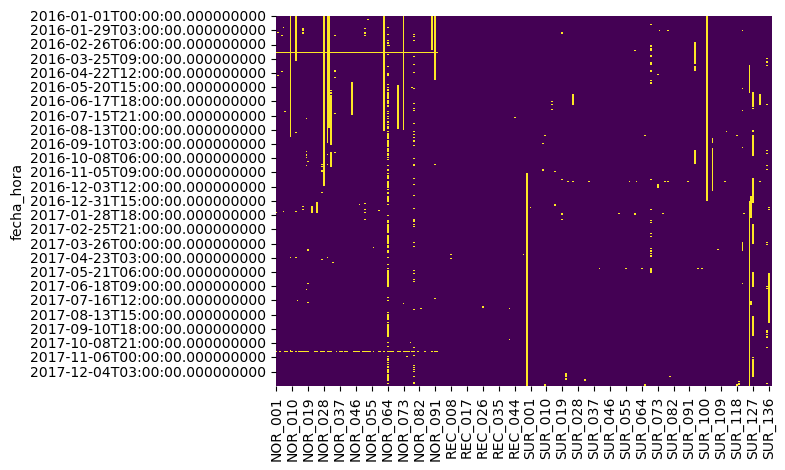

In [12]:
sns.heatmap(consumo.isna(), cbar=False, cmap="viridis")

El mapa de calor de valores ausentes revela tres patrones claros y diferenciados:

- Por un lado, se tienen **franjas horizontales**, que se corresponden a caídas globales del sistema general durante unas pocas horas. Si se trata de una caída corta (menos de unas 6 horas, respetando el ciclo natural de cambios de uso de energía), basta con una **interpolación lineal**; sino, se puede recurrir a imputar el valor de la misma hora de la anterior semana. 

- Por otro lado, se observan **franjas verticales**, que se corresponden con contadores específicos que presentan valores ausentes durante prácticamente todo el periodo temporal analizado. Es necesario **eliminar** aquellos que presenten un porcentaje elevado de valores nulos continuos, pues no es estadísticamente riguroso imputar valores a meses de lecturas inexistentes. 

- Finalmente, se tienen **pérdidas puntuales**, pequeños huecos aislados repartidos en columnas. El tratamiento de éstas es completamente equivalente al de las franjas horizontales. Su distinción es meramente conceptual. 

In [13]:
# 1) Descartar contadores crónicamente rotos (> 20% de datos faltantes)
umbral_nulos = 0.20
contadores_validos = consumo.columns[consumo.isna().mean() <= umbral_nulos]
consumo = consumo[contadores_validos]

# 2) Interpolar huecos muy cortos (menos de 6 horas, pudiéndose cambiar) linealmente
consumo = consumo.interpolate(method="time", limit=6)

# 3) Imputar los huecos restantes con el valor de la misma hora de la anterior (o posterior, si procede) semana (168 horas).
consumo = consumo.fillna(consumo.shift(168))
consumo = consumo.fillna(consumo.shift(-168))

# 4) Si tras esto queda algún hueco puntual más, aplicar interpolación final
consumo = consumo.interpolate(method="linear")

##### *2.1.2.2 - Calidad del dato en el dataset de bloques*

<Axes: ylabel='bloque'>

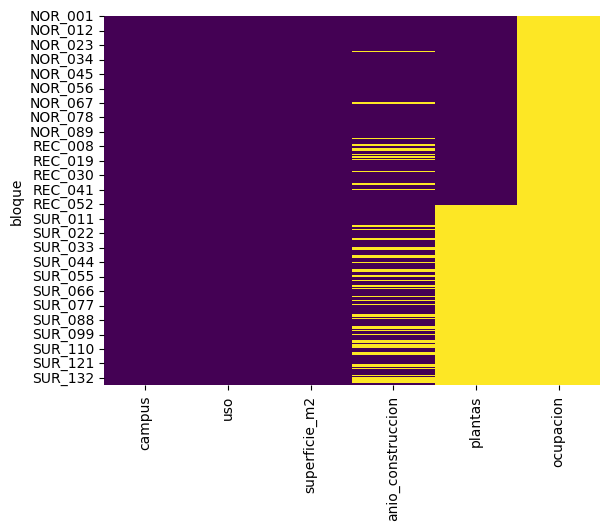

In [14]:
sns.heatmap(bloques.isna(), cbar=False, cmap="viridis")

Se observa lo siguiente: 
- Como bien dice el enunciado, la columna `ocupacion` está llena de nulos, por lo que directamente se elimina. 
- En la columna `plantas` se observa gran cantidad de nulos repartidos de forma no aleatoria. También se descarta. 
- Para `anio_construccion` consideramos conveniente imputar la mediana por campus. 

In [15]:
# 1) Eliminar columnas con demasiados nulos
bloques.drop(columns=["ocupacion", "plantas"], inplace=True)

# 2) Imputar la mediana de anio_construccion por campus
bloques["anio_construccion"] = bloques.groupby("campus", observed=False)["anio_construccion"].transform(lambda x: x.fillna(x.median()))

##### *2.1.2.3 - Calidad del dato en el dataset de meteorología*

<Axes: ylabel='fecha_hora'>

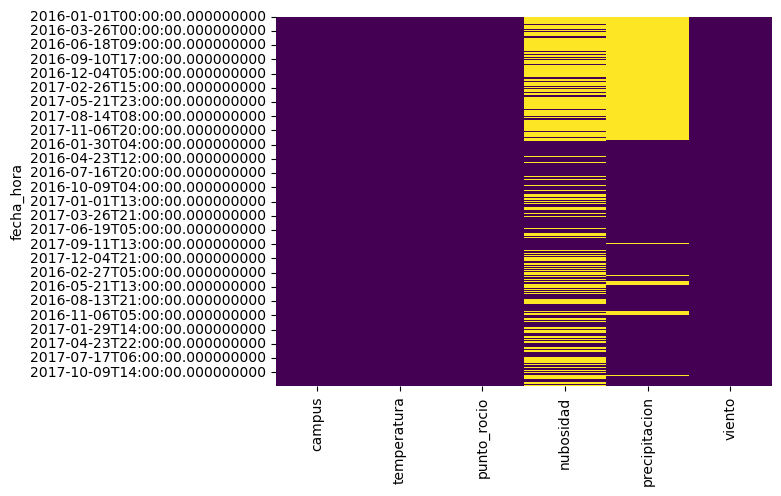

In [16]:
sns.heatmap(meteo.isna(), cbar=False, cmap="viridis")

En este caso la decisión parece sencilla: descartaremos tanto `nubosidad` como `precipitacion`. El primer caso debido a que prácticamente todo un campus no presenta información y el segundo debido a que más de la mitad de sus datos son vacíos (tal y como se indica en el enunciado). 

In [17]:
meteo.drop(columns=["nubosidad", "precipitacion"], inplace=True)

#### 2.1.3 - Construcción de la serie agregada de cada campus

A continuación se pide **obtener una serie de cada campus de su respectivo consumo por día**. 

Dado que se necesita agregar los valores tanto de todos los bloques de un campus determinado como todas las horas dentro de un día, dicha agregación se realiza en **dos dimensiones**: 

- Una **dimensión temporal** (las horas en un día) -> para ello se deben sumar los consumos de cada hora sin hacer media, pues se pretende mostrar el consumo total del día. 

- Una **dimensión espacial** (los bloques en un campus) -> para ello se deben igualmente sumar los consumos de cada bloque. 

In [18]:
consumo_agregado = pd.DataFrame()

# 1) Identificar los contadores correspondientes a cada campus
cols_nor = [col for col in consumo.columns if col.startswith('NOR')]
cols_sur = [col for col in consumo.columns if col.startswith('SUR')]
cols_rec = [col for col in consumo.columns if col.startswith('REC')]

# 3) Agregación espacial
consumo_agregado["NOR"] = consumo[cols_nor].sum(axis=1)
consumo_agregado["SUR"] = consumo[cols_sur].sum(axis=1)
consumo_agregado["REC"] = consumo[cols_rec].sum(axis=1)

# 2) Agregación temporal
consumo_agregado = consumo_agregado.resample("D").sum()

### **2.2 - Visualización**

#### 2.2.1 - Visualizaciones de consumo medio

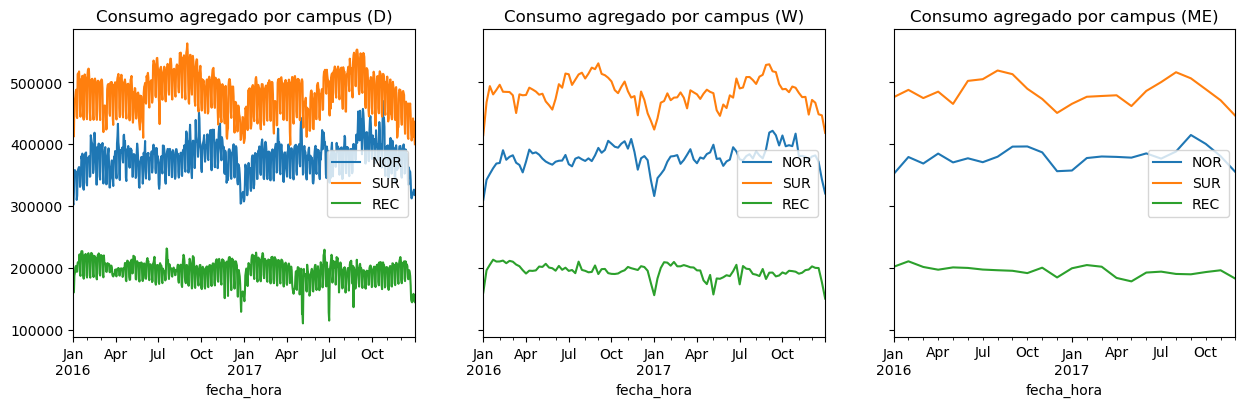

In [33]:
# Visualización de consumo medio por campus, en función de diferentes medidas de tiempo

medidas_tiempo = ["D", "W", "ME"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for medida_tiempo in medidas_tiempo:
    consumo_agregado_resample = consumo_agregado.resample(medida_tiempo).mean()
    consumo_agregado_resample.plot(ax=ax.flatten()[medidas_tiempo.index(medida_tiempo)], title=f"Consumo agregado por campus ({medida_tiempo})")

#### 2.2 - Visualización según estacionalidad